<a href="https://colab.research.google.com/github/bajichaghan-glitch/KBUstart/blob/main/202610142_%EA%B9%80%EC%9E%AC%EC%9D%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from numpy.random import randn
import numpy as np
np.random.seed(123)
import os
import matplotlib.pyplot as plt
import pandas as pd
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4)
pd.options.display.max_columns = 20
pd.options.display.max_rows = 20
pd.options.display.max_colwidth = 80

In [2]:
from numpy.random import randn

<Axes: >

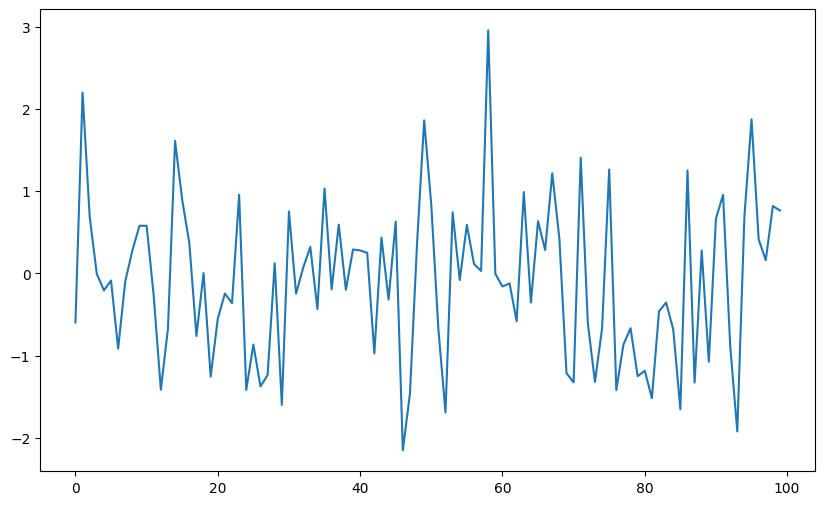

In [7]:
pd.Series(randn(100)).plot() # normal distribution (정규분포, Bell shape distibution)
#Gaussian Distribution
# 평균(mean) = 0, 분산(Dispersion, Variance)

<Axes: ylabel='Frequency'>

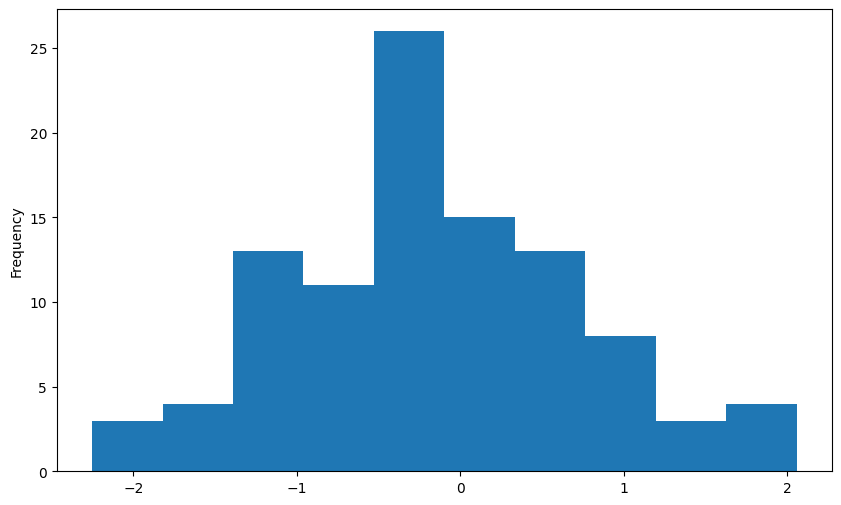

In [13]:
pd.Series(randn(100)).plot(kind="hist") # normal distribution (정규분포, Bell shape distibution)
#Gaussian Distribution
# 평균(mean) = 0, 분산(Dispersion, Variance)

<Axes: ylabel='Frequency'>

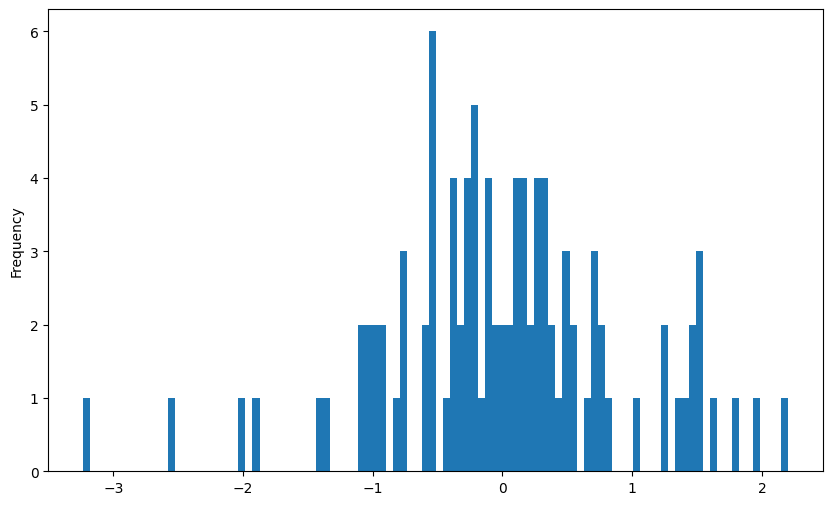

In [11]:
pd.Series(randn(100)).plot(kind="hist", bins=100) # normal distribution (정규분포, Bell shape distibution)
#Gaussian Distribution
# 평균(mean) = 0, 분산(Dispersion, Variance)

In [8]:
np.random.seed(123)
randn(10)

array([-1.0856,  0.9973,  0.283 , -1.5063, -0.5786,  1.6514, -2.4267,
       -0.4289,  1.2659, -0.8667])

In [14]:
import requests

# 1. GitHub API 전용 URL로 변경 (raw 주소가 아닌 api 주소 사용)
api_url = "https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames"

# 2. API 요청으로 디렉토리 정보 받아오기
response = requests.get(api_url)
data = response.json()

for file in data:
    print(file)

{'name': 'NationalReadMe.pdf', 'path': 'datasets/babynames/NationalReadMe.pdf', 'sha': '40b264ea297a4897f9665507ef9f1dbb94e12160', 'size': 5724, 'url': 'https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames/NationalReadMe.pdf?ref=3rd-edition', 'html_url': 'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/babynames/NationalReadMe.pdf', 'git_url': 'https://api.github.com/repos/wesm/pydata-book/git/blobs/40b264ea297a4897f9665507ef9f1dbb94e12160', 'download_url': 'https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/NationalReadMe.pdf', 'type': 'file', '_links': {'self': 'https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames/NationalReadMe.pdf?ref=3rd-edition', 'git': 'https://api.github.com/repos/wesm/pydata-book/git/blobs/40b264ea297a4897f9665507ef9f1dbb94e12160', 'html': 'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/babynames/NationalReadMe.pdf'}}
{'name': 'yob1880.txt', 'path': 'datasets/

In [18]:
# data 변수로부터 파일 이름 목록 생성
txt_files = [file['name'] for file in data if file['name'].endswith('.txt')]

# 첫 번째 텍스트 파일 이름 확인
txt_files[0]

'yob1880.txt'

In [19]:
txt_files[130]

'yob2010.txt'

In [20]:
# @title 동기방식(Syn), Blocking
import time

# 1. 측정 시작
start_time = time.perf_counter()

base_url = "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/yob{}.txt"

# 1880년부터 2011년까지 전체 데이터 읽어오기
dfs = []
names=["name", "sex", "births"]

for year in range(1880, 2011):
    url = base_url.format(year)
    # print(url)
    # pandas는 웹 URL을 직접 읽기
    df = pd.read_csv(url, names= names)
    df["year"] = year
    dfs.append(df)

names = pd.concat(dfs, ignore_index=True)

# 2. 측정 종료
end_time = time.perf_counter()

# 3. 소요 시간 계산
execution_time = end_time - start_time
print(f"전체 코드 실행 시간: {execution_time:.2f}초")

전체 코드 실행 시간: 20.25초


In [21]:
names

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880
...,...,...,...,...
1690779,Zymaire,M,5,2010
1690780,Zyonne,M,5,2010
1690781,Zyquarius,M,5,2010
1690782,Zyran,M,5,2010


In [22]:
# @title 비동기방식(Asyn), Non-Blocking
import asyncio
import io
import aiohttp

# 1. 측정 시작
start_time = time.perf_counter()

base_url = (
    "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/yob{}.txt"
)
names = ["name", "sex", "births"]


async def fetch(session, year):
    url = base_url.format(year)
    async with session.get(url) as response:
        # 텍스트 데이터를 메모리 바이너리로 변환 후 read_csv 처리
        content = await response.read()
        df = pd.read_csv(io.BytesIO(content), names=names)
        df["year"] = year
        return df


async def main():
    async with aiohttp.ClientSession() as session:
        # 1880년부터 2010년(2011 전)까지 동시 요청 생성
        tasks = [fetch(session, year) for year in range(1880, 2011)]
        dfs = await asyncio.gather(*tasks)
        return pd.concat(dfs, ignore_index=True)


# 실행 (Jupyter Notebook / Google Colab 환경)
names = await main()
# 일반 Python 스크립트(.py 파일) 실행 시 아래 주석 해제:
# users = asyncio.run(main())

# 2. 측정 종료
end_time = time.perf_counter()

# 3. 소요 시간 계산
execution_time = end_time - start_time
print(f"전체 코드 실행 시간: {execution_time:.2f}초")

전체 코드 실행 시간: 4.94초


In [23]:
names

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880
...,...,...,...,...
1690779,Zymaire,M,5,2010
1690780,Zyonne,M,5,2010
1690781,Zyquarius,M,5,2010
1690782,Zyran,M,5,2010


In [24]:
names.groupby("year")["births"].sum()

,births
year,
1880,201486
1881,192703
1882,221538
1883,216954
1884,243466
...,...
2006,3946702
2007,3986130
2008,3915955


In [26]:
names.groupby(["year","sex"])["births"].sum().unstack

<bound method Series.unstack of year  sex
1880  F        90993
      M       110493
1881  F        91955
      M       100748
1882  F       107851
              ...   
2008  M      2032310
2009  F      1827643
      M      1973359
2010  F      1759010
      M      1898382
Name: births, Length: 262, dtype: int64>

In [27]:
total_births = names.pivot_table("births", index="year",
                                 columns="sex", aggfunc=sum)
total_births.tail()

/tmp/ipykernel_4837/2884893213.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_births = names.pivot_table("births", index="year",


sex,F,M
year,,
2006,1896468,2050234
2007,1916888,2069242
2008,1883645,2032310
2009,1827643,1973359
2010,1759010,1898382


<Axes: title={'center': 'Total births by sex and year'}, xlabel='year'>

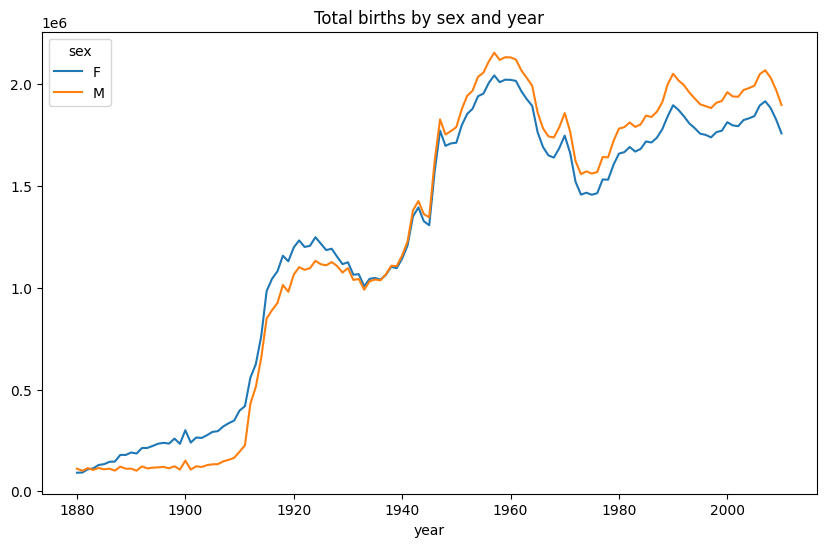

In [28]:
total_births.plot(title="Total births by sex and year")

In [29]:
import numpy as np
np.arange(20)
pd.DataFrame(np.arange(20). reshape(4, 5)).values

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [30]:
import numpy as np
np.arange(20)
np.arange(20). reshape(4, 5)

array([[ 0,  1,  2,  3,  4],
       [ 5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14],
       [15, 16, 17, 18, 19]])

In [32]:
import numpy as np
#np.arange(20)
np.arange(20).std()

np.float64(5.766281297335398)

In [ ]:
date.groupby